# PPO Zero-Init under 2-Level Telegraph Noise

Trains a PPO agent with default zero-init (no QCL warm-start) for adaptive eavesdropping on BB84 under 2-level telegraph noise. Uses the Decker reward and reports per-timestep detection rate as the security metric. Compared against the QCL switching baseline.

## 1. Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
import torch
import gymnasium as gym
from gymnasium import spaces
from scipy.optimize import minimize
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import DensityMatrix, SparsePauliOp, Statevector
from qiskit.circuit import ParameterVector

warnings.filterwarnings('ignore')
np.random.seed(42)
print('Imports loaded.')

Imports loaded.


## 2. Configuration

In [3]:
configs = [
    ('0', [1, 0]),
    ('1', [0, 1]),
    ('+', [1/np.sqrt(2),  1/np.sqrt(2)]),
    ('-', [1/np.sqrt(2), -1/np.sqrt(2)]),
]

# 2-level telegraph noise
P_LOW  = 0.05
P_HIGH = 0.25
NOISE_LEVELS = np.array([P_LOW, P_HIGH])
TRANS_PROB = 0.15

# Attack parameters (Decker et al. 2025 reward)
F_TARGET = 0.85
ALPHA = 100.0
NUM_ANGLES = 8

TRAIN_STEPS = 500
TEST_STEPS  = 200

print(f'2-level telegraph: {NOISE_LEVELS}, trans_prob={TRANS_PROB}')
print(f'Decker reward: F_AE - {ALPHA}*(F_AB - {F_TARGET})^2')
print(f'Detection metric (one-sided BB84): F_AB < {F_TARGET}')
print(f'\nF_AB without Eve at each level:')
for p in NOISE_LEVELS:
    print(f'  p={p:.2f}: F_AB = {1-p/2:.3f}, budget = {1-p/2-F_TARGET:.3f}')

2-level telegraph: [0.05 0.25], trans_prob=0.15
Decker reward: F_AE - 100.0*(F_AB - 0.85)^2
Detection metric (one-sided BB84): F_AB < 0.85

F_AB without Eve at each level:
  p=0.05: F_AB = 0.975, budget = 0.125
  p=0.25: F_AB = 0.875, budget = 0.025


## 3. Physics

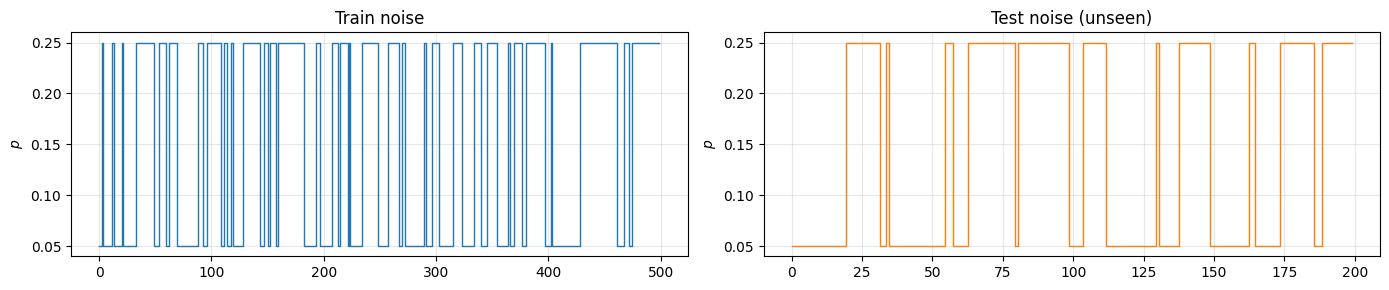

Test: p=0.05 appears 52.0% of blocks
Test: p=0.25 appears 48.0% of blocks


In [4]:
def generate_2level_noise(n_steps, p_low=P_LOW, p_high=P_HIGH, trans_prob=TRANS_PROB, seed=None):
    rng = np.random.default_rng(seed)
    noise = np.empty(n_steps)
    current_p = p_low
    for i in range(n_steps):
        noise[i] = current_p
        if rng.random() < trans_prob:
            current_p = p_high if current_p == p_low else p_low
    return noise


_projectors = {}
for _label, _ in configs:
    _projectors[_label] = SparsePauliOp.from_operator(
        Statevector.from_label(_label).to_operator())
_I = SparsePauliOp('I')
_X = SparsePauliOp('X')


def compute_noisy_fidelities(circuit, p_noise):
    f_ab, f_ae = 0.0, 0.0
    for label, _ in configs:
        rho = DensityMatrix.from_label(label)
        rho_noisy = (1 - p_noise) * rho + p_noise * rho.evolve(_X)
        rho_in = rho_noisy.tensor(DensityMatrix.from_label('0'))
        rho_out = rho_in.evolve(circuit)
        f_ab += rho_out.expectation_value(_projectors[label].expand(_I)).real
        f_ae += rho_out.expectation_value(_I.expand(_projectors[label])).real
    return f_ab / 4, f_ae / 4


_theta_vec = ParameterVector('t', length=NUM_ANGLES)

def _build_ansatz():
    qr = QuantumRegister(2, name='q')
    cr = ClassicalRegister(3, name='c')
    qc = QuantumCircuit(qr, cr)
    qc.ry(_theta_vec[0], 0); qc.ry(_theta_vec[1], 1)
    qc.rz(_theta_vec[2], 0); qc.rz(_theta_vec[3], 1)
    qc.cx(1, 0); qc.cx(0, 1)
    qc.ry(_theta_vec[4], 0); qc.ry(_theta_vec[5], 1)
    qc.rz(_theta_vec[6], 0); qc.rz(_theta_vec[7], 1)
    return qc

ANSATZ = _build_ansatz()

def bind_ansatz(angles):
    return ANSATZ.assign_parameters([float(a) for a in angles])


# Decker et al. 2025: symmetric quadratic penalty
def compute_reward(angles, p_noise):
    circ = bind_ansatz(angles)
    f_ab, f_ae = compute_noisy_fidelities(circ, p_noise)
    penalty = (f_ab - F_TARGET) ** 2
    reward = f_ae - ALPHA * penalty
    return reward, f_ab, f_ae


train_noise = generate_2level_noise(TRAIN_STEPS, seed=0)
test_noise  = generate_2level_noise(TEST_STEPS, seed=99)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3))
ax1.step(range(TRAIN_STEPS), train_noise, where='mid', color='C0', lw=1)
ax1.set_title('Train noise'); ax1.set_ylabel('$p$'); ax1.grid(alpha=0.3)
ax2.step(range(TEST_STEPS), test_noise, where='mid', color='C1', lw=1)
ax2.set_title('Test noise (unseen)'); ax2.set_ylabel('$p$'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for p in NOISE_LEVELS:
    frac = np.mean(test_noise == p)
    print(f'Test: p={p:.2f} appears {frac*100:.1f}% of blocks')

## 4. QCL Ground Truth

In [5]:
N_RESTARTS = 15

def qcl_optimise(p_noise, n_restarts=N_RESTARTS):
    best_loss = np.inf
    best_angles = None
    for _ in range(n_restarts):
        x0 = np.random.uniform(-np.pi, np.pi, NUM_ANGLES)
        res = minimize(lambda a: -compute_reward(a, p_noise)[0], x0,
                       method='COBYLA', options={'maxiter': 300, 'rhobeg': 0.5})
        if res.fun < best_loss:
            best_loss = res.fun
            best_angles = res.x.copy()
    _, f_ab, f_ae = compute_reward(best_angles, p_noise)
    return best_angles, f_ab, f_ae


print(f'QCL optimisation at {len(NOISE_LEVELS)} noise levels...')
qcl = {}
for p in NOISE_LEVELS:
    angles, fab, fae = qcl_optimise(p)
    qcl[p] = {'angles': angles, 'f_ab': fab, 'f_ae': fae}
    print(f'  p={p:.2f}: F_AB={fab:.4f}, F_AE={fae:.4f}')

print('QCL complete.')

QCL optimisation at 2 noise levels...
  p=0.05: F_AB=0.8474, F_AE=0.7241
  p=0.25: F_AB=0.8397, F_AE=0.6741
QCL complete.


## 5. RL Environment + Zero-Init PPO Training

In [6]:
class Telegraph2Env(gym.Env):
    def __init__(self):
        super().__init__()
        self.observation_space = spaces.Box(
            low=np.float32(0.0), high=np.float32(0.5), shape=(1,), dtype=np.float32)
        self.action_space = spaces.Box(
            low=np.float32(-2*np.pi), high=np.float32(2*np.pi),
            shape=(NUM_ANGLES,), dtype=np.float32)
        self.current_noise = P_LOW

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_noise = self.np_random.choice([P_LOW, P_HIGH])
        return np.array([self.current_noise], dtype=np.float32), {}

    def step(self, action):
        circ = bind_ansatz(action)
        f_ab, f_ae = compute_noisy_fidelities(circ, self.current_noise)
        # Decker reward
        penalty = (f_ab - F_TARGET) ** 2
        reward = float(f_ae - ALPHA * penalty)

        if self.np_random.random() < TRANS_PROB:
            self.current_noise = P_HIGH if self.current_noise == P_LOW else P_LOW

        obs = np.array([self.current_noise], dtype=np.float32)
        info = {'f_ab': f_ab, 'f_ae': f_ae}
        return obs, reward, False, False, info


class RewardLogger(BaseCallback):
    def __init__(self):
        super().__init__()
        self.rewards, self.f_abs, self.f_aes = [], [], []
    def _on_step(self):
        for info in self.locals.get('infos', []):
            if 'f_ab' in info:
                self.rewards.append(self.locals['rewards'][0])
                self.f_abs.append(info['f_ab'])
                self.f_aes.append(info['f_ae'])
        return True


def make_ppo(seed=42):
    env = Telegraph2Env()
    return PPO(
        'MlpPolicy', env, verbose=0,
        learning_rate=lambda prog: 1e-3 * (1 - 0.9 * prog),
        n_steps=1024, batch_size=64, n_epochs=10,
        gamma=0.99, ent_coef=0.03, clip_range=0.2, seed=seed,
        policy_kwargs=dict(log_std_init=-1.0, net_arch=[64, 64]),
    )


def verify_init(model, label):
    print(f'  [{label}] policy at initialisation:')
    for p_test in NOISE_LEVELS:
        obs = np.array([p_test], dtype=np.float32)
        action, _ = model.predict(obs, deterministic=True)
        _, fab, fae = compute_reward(action, p_test)
        print(f'    p={p_test:.2f}:  F_AB={fab:.4f}  F_AE={fae:.4f}')


TOTAL_TIMESTEPS = 150_000

# ============================================================
# Zero-init PPO (default bias, no warm-start)
# ============================================================
print(f'ZERO-INIT PPO: default bias (no warm-start)')
print(f'Training PPO for {TOTAL_TIMESTEPS:,} steps\n')

logger_zero = RewardLogger()
model_zero = make_ppo(seed=42)
verify_init(model_zero, 'zero-init')
print('\nTraining...')
model_zero.learn(total_timesteps=TOTAL_TIMESTEPS, callback=logger_zero)
print('Zero-init training complete.')
model_zero.save('ppo_2level_zeroinit')

ZERO-INIT PPO: default bias (no warm-start)
Training PPO for 150,000 steps

  [zero-init] policy at initialisation:
    p=0.05:  F_AB=0.9750  F_AE=0.5000
    p=0.25:  F_AB=0.8750  F_AE=0.5001

Training...
Zero-init training complete.


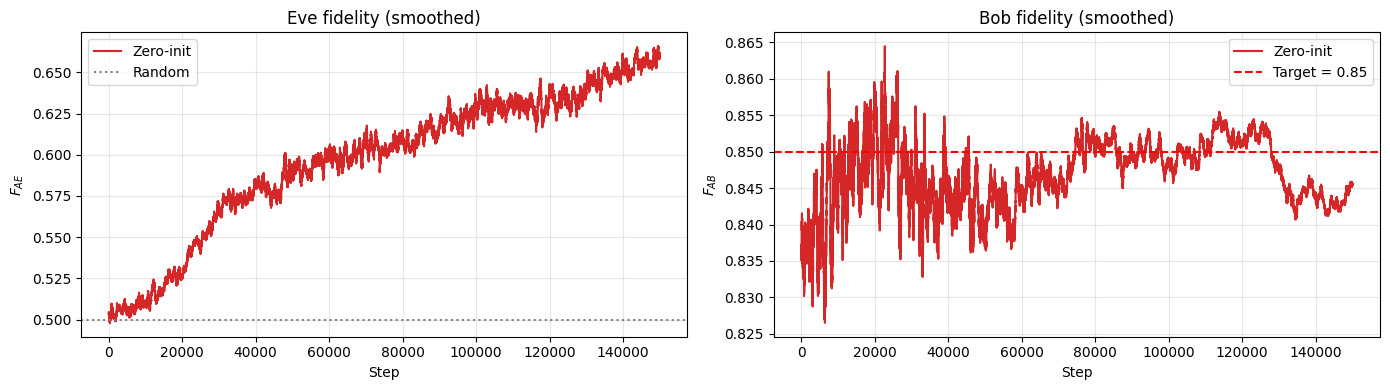


Final metrics (last 1000 training steps):
  F_AE: 0.6627
  F_AB: 0.8455


In [7]:
window = 500
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

if len(logger_zero.f_aes) >= window:
    smoothed_fae = np.convolve(logger_zero.f_aes, np.ones(window)/window, 'valid')
    axes[0].plot(smoothed_fae, color='C3', lw=1.5, label='Zero-init')
    smoothed_fab = np.convolve(logger_zero.f_abs, np.ones(window)/window, 'valid')
    axes[1].plot(smoothed_fab, color='C3', lw=1.5, label='Zero-init')

axes[0].axhline(0.5, color='gray', ls=':', label='Random')
axes[0].set_xlabel('Step'); axes[0].set_ylabel('$F_{AE}$')
axes[0].set_title('Eve fidelity (smoothed)'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].axhline(F_TARGET, color='red', ls='--', label=f'Target = {F_TARGET}')
axes[1].set_xlabel('Step'); axes[1].set_ylabel('$F_{AB}$')
axes[1].set_title('Bob fidelity (smoothed)'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\nFinal metrics (last 1000 training steps):")
print(f"  F_AE: {np.mean(logger_zero.f_aes[-1000:]):.4f}")
print(f"  F_AB: {np.mean(logger_zero.f_abs[-1000:]):.4f}")

## 6. Evaluation — Per-Timestep Detection Rate

In [8]:
def rl_policy_zero(p):
    obs = np.array([p], dtype=np.float32)
    action, _ = model_zero.predict(obs, deterministic=True)
    return action

def qcl_nearest(p):
    nearest = NOISE_LEVELS[np.argmin(np.abs(NOISE_LEVELS - p))]
    return qcl[nearest]['angles']


def eval_policy(policy_fn, test_noise):
    results = {'f_ab': [], 'f_ae': [], 'reward': []}
    for p in test_noise:
        angles = policy_fn(p)
        r, fab, fae = compute_reward(angles, p)
        results['f_ab'].append(fab)
        results['f_ae'].append(fae)
        results['reward'].append(r)
    return {k: np.array(v) for k, v in results.items()}


all_methods = {
    'RL zero-init':  eval_policy(rl_policy_zero, test_noise),
    'QCL Switching': eval_policy(qcl_nearest, test_noise),
}

print('=' * 80)
print('2-LEVEL TELEGRAPH EVALUATION  —  Decker reward, one-sided detection')
print('=' * 80)
print(f"\n{'Method':<22} {'<F_AB>':>8} {'<F_AE>':>8} {'min F_AB':>10} {'Det. rate':>12}")
print('-' * 80)
for name, res in all_methods.items():
    fab_mean = res['f_ab'].mean()
    fae_mean = res['f_ae'].mean()
    fab_min  = res['f_ab'].min()
    det_rate = np.mean(res['f_ab'] < F_TARGET)
    print(f'{name:<22} {fab_mean:>8.4f} {fae_mean:>8.4f} {fab_min:>10.4f} {det_rate*100:>10.1f} %')

# Per-level breakdown
print(f"\n{'Method':<22} {'Level':>6} {'<F_AB>':>8} {'<F_AE>':>8} {'Det. rate':>12}")
print('-' * 65)
for name, res in all_methods.items():
    for p in NOISE_LEVELS:
        mask = test_noise == p
        if mask.sum() == 0: continue
        fab = res['f_ab'][mask].mean()
        fae = res['f_ae'][mask].mean()
        det = np.mean(res['f_ab'][mask] < F_TARGET)
        print(f'{name:<22} {p:>6.2f} {fab:>8.4f} {fae:>8.4f} {det*100:>10.1f} %')
    print()

2-LEVEL TELEGRAPH EVALUATION  —  Decker reward, one-sided detection

Method                   <F_AB>   <F_AE>   min F_AB    Det. rate
--------------------------------------------------------------------------------
RL zero-init             0.8532   0.6841     0.8517        0.0 %
QCL Switching            0.8437   0.7001     0.8397      100.0 %

Method                  Level   <F_AB>   <F_AE>    Det. rate
-----------------------------------------------------------------
RL zero-init             0.05   0.8546   0.7204        0.0 %
RL zero-init             0.25   0.8517   0.6447        0.0 %

QCL Switching            0.05   0.8474   0.7241      100.0 %
QCL Switching            0.25   0.8397   0.6741      100.0 %



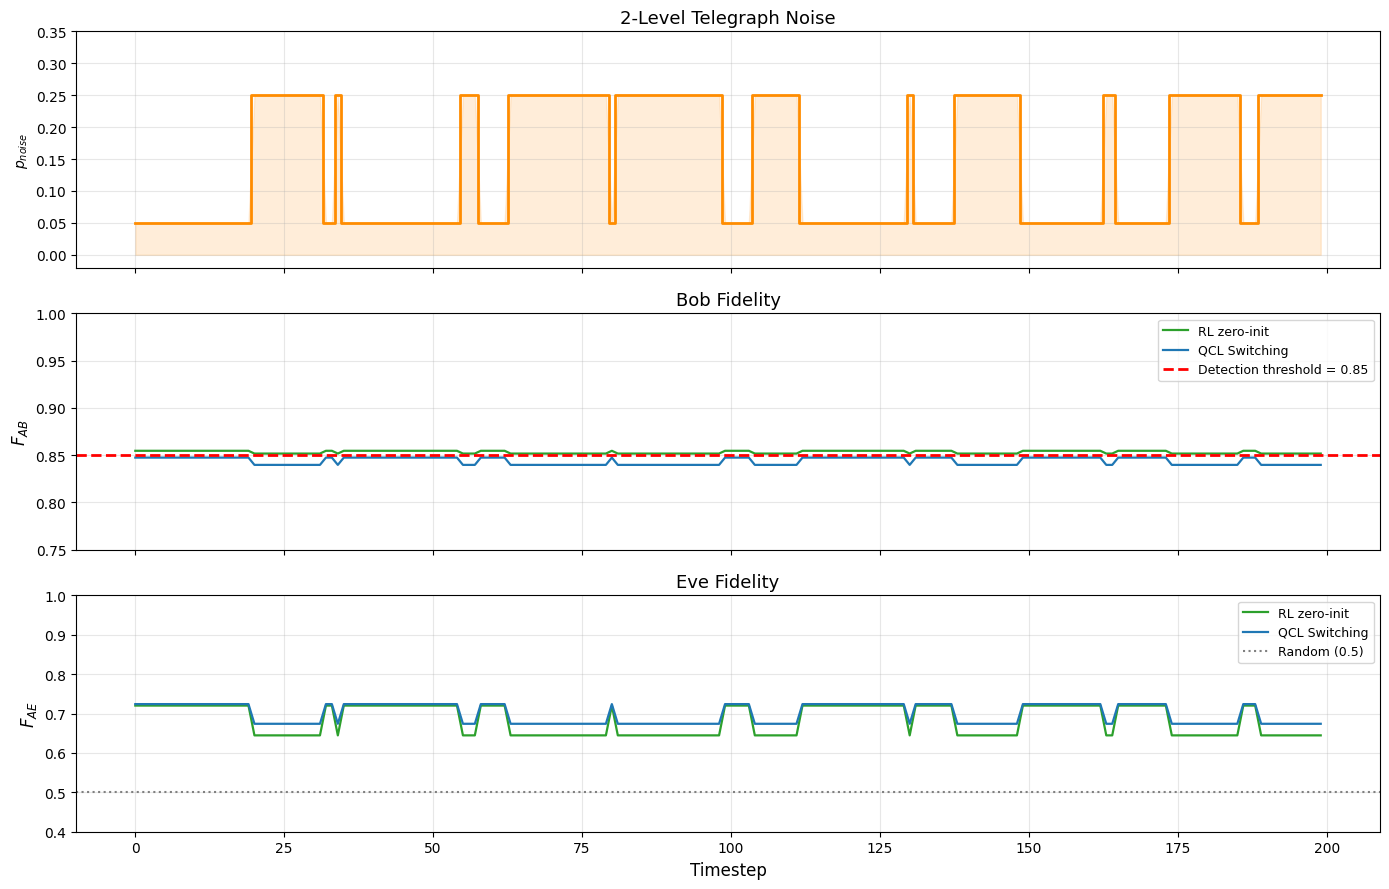

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

ax = axes[0]
ax.step(range(TEST_STEPS), test_noise, where='mid', color='darkorange', lw=2)
ax.fill_between(range(TEST_STEPS), 0, test_noise, alpha=0.15, color='darkorange')
ax.set_ylabel('$p_{noise}$'); ax.set_title('2-Level Telegraph Noise', fontsize=13)
ax.set_ylim(-0.02, 0.35); ax.grid(alpha=0.3)

ax = axes[1]
for name, color in [('RL zero-init', 'C2'), ('QCL Switching', 'C0')]:
    fab = all_methods[name]['f_ab']
    ax.plot(fab, color=color, lw=1.6, label=name)
ax.axhline(F_TARGET, color='red', ls='--', lw=2, label=f'Detection threshold = {F_TARGET}')
ax.set_ylabel('$F_{AB}$', fontsize=12); ax.set_title('Bob Fidelity', fontsize=13)
ax.legend(fontsize=9); ax.grid(alpha=0.3); ax.set_ylim(0.75, 1.0)

ax = axes[2]
for name, color in [('RL zero-init', 'C2'), ('QCL Switching', 'C0')]:
    fae = all_methods[name]['f_ae']
    ax.plot(fae, color=color, lw=1.6, label=name)
ax.axhline(0.5, color='gray', ls=':', lw=1.5, label='Random (0.5)')
ax.set_ylabel('$F_{AE}$', fontsize=12); ax.set_xlabel('Timestep', fontsize=12)
ax.set_title('Eve Fidelity', fontsize=13)
ax.legend(fontsize=9); ax.grid(alpha=0.3); ax.set_ylim(0.4, 1.0)
plt.tight_layout(); plt.show()

## 7. Summary

In [10]:
import pandas as pd

rows = []
for name, res in all_methods.items():
    rows.append({
        'Method': name,
        '<F_AB>': f"{res['f_ab'].mean():.4f}",
        '<F_AE>': f"{res['f_ae'].mean():.4f}",
        'min F_AB': f"{res['f_ab'].min():.4f}",
        '<Reward>': f"{res['reward'].mean():.4f}",
        'Det. rate': f"{np.mean(res['f_ab'] < F_TARGET)*100:.1f} %",
    })

display(pd.DataFrame(rows).set_index('Method'))

,<F_AB>,<F_AE>,min F_AB,<Reward>,Det. rate
Method,,,,,
RL zero-init,0.8532,0.6841,0.8517,0.6828,0.0 %
QCL Switching,0.8437,0.7001,0.8397,0.6947,100.0 %
